# Exercise: Can an encoder tell blood cells apart?

Each image is one blood cell. There are **8 types** of cell, like `neutrophil`, `lymphocyte`, and `platelet`. Doctors count these types to check a patient's health.

We used a pretrained encoder, [CLIP](https://huggingface.co/openai/clip-vit-base-patch32) from OpenAI, to turn each image into a row of 512 numbers. It is the same encoder as in lecture 17. Your job is to fit a model on those numbers and see how well it names the cell type.

> Aside: The images come from [BloodMNIST](https://medmnist.com/), a set of small blood cell photos.

## Setup

In [42]:
library('tidymodels')
library('embed')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

## 1. Load the data

Run this cell. It loads the table and gives each number in `label` its cell type name.

In [43]:
cell_types <- c('basophil', 'eosinophil', 'erythroblast', 'immature granulocyte',
                'lymphocyte', 'monocyte', 'neutrophil', 'platelet')

blood <- readr::read_csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/bloodmnist-emb.csv.gz', show_col_types = FALSE) |>
    mutate(label = factor(label, levels = 0:7, labels = cell_types))

blood |> select(label, dim_1:dim_5) |> head()

 [100%] Downloaded 5609398 bytes...
                                                                              

  label                dim_1     dim_2    dim_3    dim_4     dim_5    
1 immature granulocyte  0.085279 -0.26402 0.063462  0.025801 -0.098319
2 basophil             -0.012049 -0.15497 0.148770  0.023569 -0.211840
3 eosinophil            0.030726 -0.29901 0.122680  0.018524 -0.351250
4 immature granulocyte -0.036050 -0.32184 0.104240 -0.065245 -0.259210
5 eosinophil           -0.027404 -0.25296 0.138080  0.042795 -0.144170
6 eosinophil            0.103920 -0.35111 0.196130 -0.043099 -0.342830

In [44]:
blood |> count(label)

  label                n  
1 basophil             244
2 eosinophil           624
3 erythroblast         311
4 immature granulocyte 579
5 lymphocyte           243
6 monocyte             284
7 neutrophil           666
8 platelet             470

**Check:** how many rows? How many columns? Which cell type is the most common? Which is the rarest?

## 2. Split the data

Run this cell. Do not change it.

- `train`: half of the images. The model learns from these.
- `test`: the other half. The model has never seen these. We measure accuracy here.

In [45]:
set.seed(512)

split <- initial_split(blood, prop = 0.5, strata = label)
train <- training(split)
test  <- testing(split)

nrow(train)

[1] 1709

## 3. Visualize with UMAP

We cannot plot 512 dimensions at once. **UMAP** squeezes all the dimensions into 2 new columns, `UMAP1` and `UMAP2`. Similar images will have similar `UMAP1` and `UMAP2` values.

Run the cell. It makes the 2 UMAP columns for the `train` images. (It takes a few seconds.)

In [46]:
set.seed(1)

umap_coords <- recipe(label ~ ., data = train) |>
    step_umap(all_predictors(), num_comp = 2) |>
    prep() |>
    bake(new_data = NULL)

umap_coords |> head()

  label      UMAP1       UMAP2     
1 eosinophil  0.61428434  1.9936582
2 eosinophil  6.60134363  6.0641437
3 eosinophil -1.22991598  3.4552143
4 lymphocyte -0.07602637 -2.3846037
5 lymphocyte -0.09495977 -1.8547384
6 monocyte   -0.07982555  0.5347311

**Your turn:** plot `UMAP1` against `UMAP2`. Color the points by `label`.

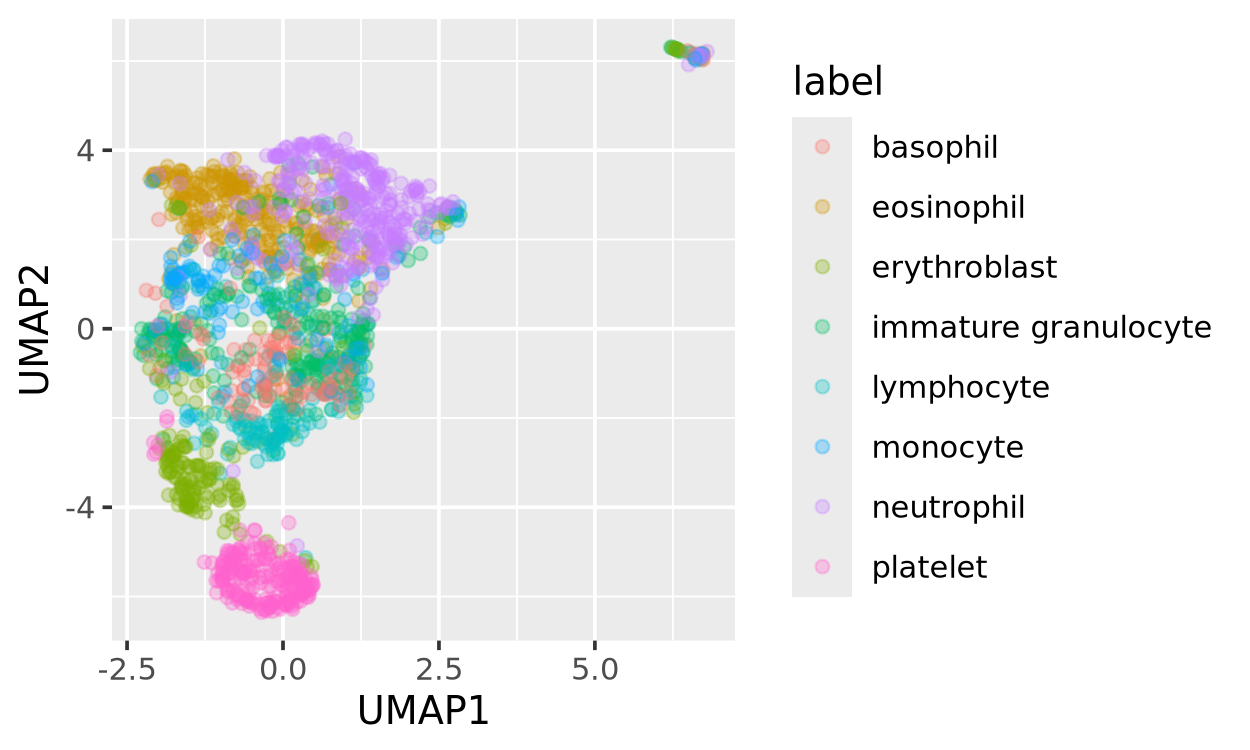

In [47]:
# Chart code goes here
ggplot(umap_coords, aes(x = UMAP1, y = UMAP2, color = label)) +
    geom_point(alpha = 0.3)

**Check:** do the cell types land in different places?

- Do you see clear groups? Are they perfectly separate?
- Which cell types are hard to tell apart?

## 4. Fit a random forest

Fit a random forest on `train`. Use the formula `label ~ .` (all the `dim_` columns are predictors).

```r
rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger')
```

In [48]:
set.seed(512)

bloodcell_fit <- rand_forest(trees = 200) |>
    set_mode('classification') |>
    set_engine('ranger') |>
    fit(label ~ ., data = train)

bloodcell_fit

parsnip model object

Ranger result

Call:
 ranger::ranger(x = maybe_data_frame(x), y = y, num.trees = 200,      num.threads = 1, verbose = FALSE, seed = sample.int(10^5,          1), probability = TRUE) 

Type:                             Probability estimation 
Number of trees:                  200 
Sample size:                      1709 
Number of independent variables:  512 
Mtry:                             22 
Target node size:                 10 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error (Brier s.):  0.3072079 

## 5. Evaluate on the test set

Find the accuracy of your model on `test`.

<details>
<summary>Hint: how do I find the accuracy?</summary>

1. `predict()` gives the predicted class for each test image.
2. `bind_cols()` puts it next to the true `label`.
3. `accuracy()` compares them.

```r
predict(fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)
```

Here `fit` is the name of your fitted model. Use your own name.

</details>

In [49]:
predict(bloodcell_fit, new_data = test) |>
    bind_cols(test) |>
    accuracy(truth = label, estimate = .pred_class)

  .metric  .estimator .estimate
1 accuracy multiclass 0.8206776

**Check:** with 8 types, guessing at random would get about 0.13. A good model gets about 0.80 to 0.85 on the test images. How does yours compare?

- Is the accuracy on `train` higher than on `test`? What does that tell you?

## 6. Bonus: which cells does it mix up?

Accuracy is one number for all 8 types. A **confusion matrix** shows which types the model confuses.

Make one with `conf_mat()`, then look back at your UMAP. Do the types that overlap in the UMAP get mixed up by the model?

In [50]:
test_preds <- predict(rf_fit, new_data = test) |>
    bind_cols(test)

conf_mat(test_preds, truth = label, estimate = .pred_class)

                      Truth
Prediction             basophil eosinophil erythroblast immature granulocyte
  basophil                   67          0            0                    5
  eosinophil                  8        276            2                    6
  erythroblast                0          0          132                    0
  immature granulocyte       42          8           10                  241
  lymphocyte                  4          0            2                    4
  monocyte                    0          1            1                    4
  neutrophil                  0         20            0                   23
  platelet                    2          1            7                    1
                      Truth
Prediction             lymphocyte monocyte neutrophil platelet
  basophil                      6        1          0        0
  eosinophil                    5        8          9        0
  erythroblast                 19        0          1        7

*Your answer:* Which cell types does the model mix up? Why do you think so?

The model sometimes mixes up a neutrophil as an eosinophil, granulocyte, or monocyte. Additionally, it sometimes confuses an immature granulocyte as an basophil, lymphocyte, or monocyte. This may be due to similarities between the cells visually that the model is having trouble differentiating (and I would too, I'm not an immunologist haha). 